In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
import os

# Define dataset path
data_dir = "C:/Users/91994/Desktop/P_Ex_Split"  # Update this with actual path

# Image parameters
IMG_SIZE = 128  # Resize to 128x128
BATCH_SIZE = 32

# Data augmentation & loading
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
train_generator = datagen.flow_from_directory(
    data_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='categorical', subset='training')
val_generator = datagen.flow_from_directory(
    data_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='categorical', subset='validation')

# Load ResNet50 without top layers
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False  # Freeze base model layers

# Build Model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(len(train_generator.class_indices), activation='softmax')  # 10 classes
])

# Compile Model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Train Model
epochs = 25
model.fit(train_generator, validation_data=val_generator, epochs=epochs)

# Save Model
model.save("ambulance_classifier_resnet50.h5")

Found 3391 images belonging to 3 classes.
Found 846 images belonging to 3 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step


C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
 34/106 ━━━━━━━━━━━━━━━━━━━━ 1:13 1s/step - accuracy: 0.5765 - loss: 0.9717

C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\PIL\Image.py:1000: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


106/106 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.6298 - loss: 0.9436 - val_accuracy: 0.6986 - val_loss: 0.8213
Epoch 2/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.6818 - loss: 0.8906 - val_accuracy: 0.6986 - val_loss: 0.8229
Epoch 3/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.7074 - loss: 0.8398 - val_accuracy: 0.6986 - val_loss: 0.8409
Epoch 4/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.6962 - loss: 0.8474 - val_accuracy: 0.6986 - val_loss: 0.8327
Epoch 5/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.6923 - loss: 0.8542 - val_accuracy: 0.6986 - val_loss: 0.8263
Epoch 6/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.6965 - loss: 0.8524 - val_accuracy: 0.6986 - val_loss: 0.8263
Epoch 7/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.6940 - loss: 0.8443 - val_accuracy: 0.6986 - val_loss: 0.8332
Epoch 8/25
106/106 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.6990 - loss: 0.8510 - val_accuracy: 0.698

In [3]:
val_loss, val_acc = model.evaluate(val_generator)
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation Loss: {val_loss:.4f}")


27/27 ━━━━━━━━━━━━━━━━━━━━ 20s 752ms/step - accuracy: 0.6982 - loss: 0.8441
Validation Accuracy: 0.6986
Validation Loss: 0.8444


In [4]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Get true labels and predictions
y_true = val_generator.classes
y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1)

# Print classification report
print(classification_report(y_true, y_pred_classes, target_names=val_generator.class_indices.keys()))


27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 689ms/step
              precision    recall  f1-score   support

        test       0.00      0.00      0.00       129
       train       0.70      1.00      0.82       591
         val       0.00      0.00      0.00       126

    accuracy                           0.70       846
   macro avg       0.23      0.33      0.27       846
weighted avg       0.49      0.70      0.57       846



C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} i

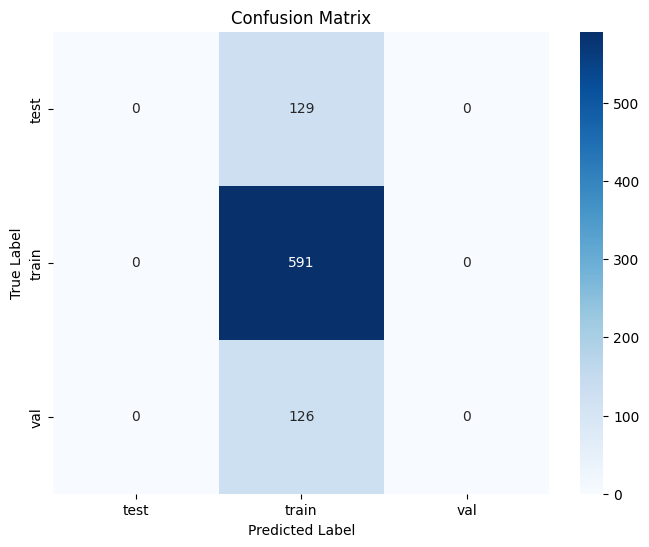

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=val_generator.class_indices.keys(), yticklabels=val_generator.class_indices.keys())
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [6]:
# Save the trained model to the specified directory
model.save("C:/Users/91994/Desktop/P_Ex_Split/resnet50_70percent.h5")

print("Model saved successfully at C:/Users/91994/Desktop/P_Ex_Split/resnet50_70percent.h5")


Model saved successfully at C:/Users/91994/Desktop/P_Ex_Split/resnet50_70percent.h5


In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import os

# ✅ Update dataset path
data_dir = "C:/Users/91994/Desktop/P_Ex_Split"

# ✅ Image settings
IMG_SIZE = 128  
BATCH_SIZE = 32  

# ✅ Apply data augmentation to improve generalization
datagen = ImageDataGenerator(
    rescale=1./255, validation_split=0.2, 
    rotation_range=30, width_shift_range=0.2,
    height_shift_range=0.2, horizontal_flip=True,
    zoom_range=0.2
)

train_generator = datagen.flow_from_directory(
    os.path.join(data_dir, "train"),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = datagen.flow_from_directory(
    os.path.join(data_dir, "val"),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# ✅ Compute class weights to handle imbalance
class_labels = list(train_generator.class_indices.keys())
num_samples = train_generator.classes
class_weights = compute_class_weight("balanced", classes=np.unique(num_samples), y=num_samples)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Class Weights:", class_weights_dict)

# ✅ Load MobileNetV2 (pretrained, lightweight)
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False  # Freeze base model layers

# ✅ Build the model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(len(train_generator.class_indices), activation='softmax')  
])

# ✅ Compile model with tuned learning rate
model.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])

# Train model without class_weight
epochs = 30  
model.fit(train_generator, validation_data=val_generator, epochs=epochs)


# ✅ Evaluate model
loss, acc = model.evaluate(val_generator)
print(f"Final Validation Accuracy: {acc:.4f}, Loss: {loss:.4f}")


Found 2959 images belonging to 10 classes.
Found 632 images belonging to 10 classes.
Class Weights: {0: 0.19939353099730459, 1: 0.7342431761786601, 2: 2.31171875, 3: 2.293798449612403, 4: 3.7455696202531645, 5: 2.31171875, 6: 1.30929203539823, 7: 2.2082089552238804, 8: 2.529059829059829, 9: 2.2587786259541986}


C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
25/93 ━━━━━━━━━━━━━━━━━━━━ 40s 592ms/step - accuracy: 0.3620 - loss: 2.1363

KeyboardInterrupt: 

In [19]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

# ✅ Step 1: Set Up ImageDataGenerator (Ensure class_mode is categorical)
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    r"C:\Users\91994\Desktop\P_Ex_Split\train",  # Replace with your train folder path
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"  # ✅ Ensures labels are in one-hot encoding
)

val_generator = val_datagen.flow_from_directory(
    r"C:\Users\91994\Desktop\P_Ex_Split\train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

# ✅ Step 2: Print class indices & Verify Class Weights
print("Class indices:", train_generator.class_indices)

# Define class weights based on dataset imbalance
class_counts = {"Ambulance": 1484, "Bus": 128, "Car": 130, "deliveryTruck": 80, "Fire_Truck": 128,
                "Tractor": 136, "Truck": 119, "Big_Truck": 404, "Van": 132, "MPV": 226}

# Ensure class names match folder names
num_classes = 10
class_weights_dict = {i: class_weights_dict.get(i, 1.0) for i in range(num_classes)}

print("Class indices:", train_generator.class_indices)
print("Class weights:", class_weights_dict)

print("Class Weights:", class_weights_dict)

# ✅ Step 3: Define Model (MobileNetV2)
base_model = tf.keras.applications.MobileNetV2=(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False  # Freeze base model

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')  # 10 classes
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# ✅ Step 4: Debug Batch Output Format
batch_images, batch_labels = next(train_generator)
print("Batch Image Shape:", batch_images.shape)  # Should be (batch_size, 224, 224, 3)
print("Batch Label Shape:", batch_labels.shape)  # Should be (batch_size, 10)

# ✅ Step 5: Train Model with Correct Class Weights
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
epochs = 30

batch = next(iter(train_generator))
print("Batch Structure:", type(batch))
print("Image Shape:", batch[0].shape)
print("Label Shape:", batch[1].shape)
print("Data Type of Images:", batch[0].dtype)
print("Data Type of Labels:", batch[1].dtype)

model.fit(train_generator, validation_data=val_generator, epochs=epochs,
          class_weight=class_weights_dict, callbacks=[early_stopping])

# ✅ Step 6: Save Model
model.save("C:/Users/91994/Desktop/P_Ex_Split/mobilenetv2_classifier.h5")

print("Model training complete and saved successfully!")

Found 2959 images belonging to 10 classes.
Found 2959 images belonging to 10 classes.
Class indices: {'Ambulance': 0, 'Big_Truck': 1, 'Bus': 2, 'Car': 3, 'DeliveryTruck': 4, 'Fire_Truck': 5, 'MPV': 6, 'Tractor': 7, 'Truck': 8, 'Van': 9}
Class indices: {'Ambulance': 0, 'Big_Truck': 1, 'Bus': 2, 'Car': 3, 'DeliveryTruck': 4, 'Fire_Truck': 5, 'MPV': 6, 'Tractor': 7, 'Truck': 8, 'Van': 9}
Class weights: {0: 0.19993261455525607, 1: 0.7344059405940594, 2: 2.31796875, 3: 2.2823076923076924, 4: 1.0, 5: 2.31796875, 6: 1.3128318584070797, 7: 2.1816176470588236, 8: 2.4932773109243698, 9: 2.2477272727272726}
Class Weights: {0: 0.19993261455525607, 1: 0.7344059405940594, 2: 2.31796875, 3: 2.2823076923076924, 4: 1.0, 5: 2.31796875, 6: 1.3128318584070797, 7: 2.1816176470588236, 8: 2.4932773109243698, 9: 2.2477272727272726}
Batch Image Shape: (32, 224, 224, 3)
Batch Label Shape: (32, 10)
Batch Structure: <class 'tuple'>
Image Shape: (32, 224, 224, 3)
Label Shape: (32, 10)
Data Type of Images: float32


InvalidArgumentError: Graph execution error:

Detected at node PyFunc defined at (most recent call last):
<stack traces unavailable>
TypeError: `generator` yielded an element that did not match the expected structure. The expected structure was (tf.float32, tf.float32, tf.float32), but the yielded element was (array([[[[0.15686275, 0.18039216, 0.227451  ],
         [0.15686275, 0.18039216, 0.227451  ],
         [0.5176471 , 0.5411765 , 0.59607846],
         ...,
         [0.09019608, 0.14117648, 0.16470589],
         [0.23529413, 0.28627452, 0.30980393],
         [0.23529413, 0.28627452, 0.30980393]],

        [[0.15686275, 0.18039216, 0.227451  ],
         [0.15686275, 0.18039216, 0.227451  ],
         [0.5176471 , 0.5411765 , 0.59607846],
         ...,
         [0.09019608, 0.14117648, 0.16470589],
         [0.23529413, 0.28627452, 0.30980393],
         [0.23529413, 0.28627452, 0.30980393]],

        [[0.09019608, 0.12156864, 0.17254902],
         [0.09019608, 0.12156864, 0.17254902]

In [16]:
num_classes = 10
class_weights_dict = {i: class_weights_dict.get(i, 1.0) for i in range(num_classes)}

print("Class indices:", train_generator.class_indices)
print("Class weights:", class_weights_dict)


Class indices: {'Ambulance': 0, 'Big_Truck': 1, 'Bus': 2, 'Car': 3, 'DeliveryTruck': 4, 'Fire_Truck': 5, 'MPV': 6, 'Tractor': 7, 'Truck': 8, 'Van': 9}
Class weights: {0: 0.19993261455525607, 1: 0.7344059405940594, 2: 2.31796875, 3: 2.2823076923076924, 4: 1.0, 5: 2.31796875, 6: 1.3128318584070797, 7: 2.1816176470588236, 8: 2.4932773109243698, 9: 2.2477272727272726}


In [21]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import os

# ✅ Step 1: Define dataset directories
train_dir = "C:/Users/91994/Desktop/P_Ex_Split/train"
val_dir = "C:/Users/91994/Desktop/P_Ex_Split/val"
test_dir = "C:/Users/91994/Desktop/P_Ex_Split/test"

# ✅ Step 2: Define ImageDataGenerator for Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1.0 / 255)
test_datagen = ImageDataGenerator(rescale=1.0 / 255)

# ✅ Step 3: Load Dataset
batch_size = 32
img_size = (224, 224)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",  # Ensures one-hot encoding
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)
"""
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical"
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)"""

# ✅ Step 4: Define MobileNetV2 Model
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(128, activation="relu")(x)
x = Dense(64, activation="relu")(x)
output_layer = Dense(len(train_generator.class_indices), activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output_layer)

# ✅ Step 5: Compile Model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

# ✅ Step 6: Class Weights (Handling Imbalance)
class_weights = {
    0: 0.1999, 1: 0.7344, 2: 2.3180, 3: 2.2823, 4: 1.0,
    5: 2.3180, 6: 1.3128, 7: 2.1816, 8: 2.4933, 9: 2.2477
}

# ✅ Step 7: Train Model
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model.fit(train_generator,
          validation_data=val_generator,
          epochs=30,
          class_weight=class_weights,
          callbacks=[early_stopping])

# ✅ Step 8: Save Model
model.save("C:/Users/91994/Desktop/P_Ex_Split/mobilenetv2_classifier.h5")

# ✅ Step 9: Evaluate Model on Test Set
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.4f}")


Found 2959 images belonging to 10 classes.
Found 632 images belonging to 10 classes.
Found 646 images belonging to 10 classes.
Epoch 1/30


InvalidArgumentError: Graph execution error:

Detected at node PyFunc defined at (most recent call last):
<stack traces unavailable>
TypeError: `generator` yielded an element that did not match the expected structure. The expected structure was (tf.float32, tf.float32, tf.float32), but the yielded element was (array([[[[0.37384507, 0.42378196, 0.32822528],
         [0.38823533, 0.43529415, 0.34117648],
         [0.38934243, 0.43640125, 0.34228358],
         ...,
         [0.339062  , 0.36613807, 0.28023848],
         [0.3357096 , 0.36529994, 0.27688608],
         [0.33479765, 0.3661702 , 0.27597412]],

        [[0.36282814, 0.41496843, 0.31831005],
         [0.38823533, 0.43529415, 0.34117648],
         [0.38824072, 0.43529955, 0.3411819 ],
         ...,
         [0.35028467, 0.3816572 , 0.29146114],
         [0.3553133 , 0.38668585, 0.29648978],
         [0.35686275, 0.38823533, 0.29803923]],

        [[0.35181123, 0.40615487, 0.30839482],
         [0.38414967, 0.4320256 , 0.3374994 ]

In [22]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# ✅ Step 1: Define Paths
train_dir = r"C:\Users\91994\Desktop\P_Ex_Split\train"
val_dir = r"C:\Users\91994\Desktop\P_Ex_Split\val"
test_dir = r"C:\Users\91994\Desktop\P_Ex_Split\test"

# ✅ Step 2: Image Data Generators
train_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
val_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

# ✅ Step 3: Load Images
img_size = (224, 224)
batch_size = 32

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

# ✅ Step 4: Load MobileNetV2 Model
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dense(10, activation="softmax")(x)  # 10 classes

model = Model(inputs=base_model.input, outputs=x)

# ✅ Step 5: Compile Model
class_weights = {
    0: 0.1999, 1: 0.7344, 2: 2.3179, 3: 2.2823, 4: 1.0,
    5: 2.3179, 6: 1.3128, 7: 2.1816, 8: 2.4932, 9: 2.2477
}

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

# ✅ Step 6: Train Model
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model.fit(train_generator,
          validation_data=val_generator,
          epochs=30,
          class_weight=class_weights,
          callbacks=[early_stopping])

# ✅ Step 7: Save Model
model.save(r"C:\Users\91994\Desktop\P_Ex_Split\mobilenetv2_classifier.h5")

print("🎉 Model training completed and saved successfully!")


Found 2959 images belonging to 10 classes.
Found 632 images belonging to 10 classes.
Found 646 images belonging to 10 classes.
Epoch 1/30


InvalidArgumentError: Graph execution error:

Detected at node PyFunc defined at (most recent call last):
<stack traces unavailable>
TypeError: `generator` yielded an element that did not match the expected structure. The expected structure was (tf.float32, tf.float32, tf.float32), but the yielded element was (array([[[[0.8862746 , 0.8980393 , 0.92549026],
         [0.8862746 , 0.8980393 , 0.92549026],
         [0.8980393 , 0.909804  , 0.93725497],
         ...,
         [0.86274517, 0.87843144, 0.91372555],
         [0.86274517, 0.87843144, 0.91372555],
         [0.86274517, 0.87843144, 0.91372555]],

        [[0.8862746 , 0.8980393 , 0.92549026],
         [0.8862746 , 0.8980393 , 0.92549026],
         [0.8980393 , 0.909804  , 0.93725497],
         ...,
         [0.86274517, 0.87843144, 0.91372555],
         [0.86274517, 0.87843144, 0.91372555],
         [0.86274517, 0.87843144, 0.91372555]],

        [[0.8862746 , 0.8980393 , 0.92549026],
         [0.8862746 , 0.8980393 , 0.92549026]

C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\PIL\Image.py:1000: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [24]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# ✅ Step 1: Define Paths
train_dir = r"C:\Users\91994\Desktop\P_Ex_Split\train"
val_dir = r"C:\Users\91994\Desktop\P_Ex_Split\val"
test_dir = r"C:\Users\91994\Desktop\P_Ex_Split\test"

# ✅ Step 2: Image Data Generators
train_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
val_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

# ✅ Step 3: Load Images
img_size = (224, 224)
batch_size = 32

def custom_generator(generator):
    for img_batch, label_batch in generator:
        # Convert to float32 explicitly
        yield (tf.convert_to_tensor(img_batch, dtype=tf.float32), 
               tf.convert_to_tensor(label_batch, dtype=tf.float32))

train_generator = custom_generator(train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode="categorical", shuffle=True))

val_generator = custom_generator(val_datagen.flow_from_directory(
    val_dir, target_size=img_size, batch_size=batch_size, class_mode="categorical"))

test_generator = custom_generator(test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode="categorical", shuffle=False))

# ✅ Step 4: Load MobileNetV2 Model
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)  
output = Dense(10, activation="softmax")(x)  # ✅ Ensure this is assigned

model = Model(inputs=base_model.input, outputs=output)  # ✅ Use `output` here


# ✅ Step 5: Compile Model
class_weights = {
    0: 0.1999, 1: 0.7344, 2: 2.3179, 3: 2.2823, 4: 1.0,
    5: 2.3179, 6: 1.3128, 7: 2.1816, 8: 2.4932, 9: 2.2477
}

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

# ✅ Step 6: Train Model
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model.fit(train_generator,
          validation_data=val_generator,
          epochs=30,
          class_weight=class_weights,
          callbacks=[early_stopping],
          steps_per_epoch=100,   # Adjust as needed
          validation_steps=50)   # Adjust as needed

# ✅ Step 7: Save Model
model.save(r"C:\Users\91994\Desktop\P_Ex_Split\mobilenetv2_classifier.h5")

print("🎉 Model training completed and saved successfully!")


Found 2959 images belonging to 10 classes.
Found 632 images belonging to 10 classes.
Found 646 images belonging to 10 classes.


ValueError: Argument `class_weight` is not supported for Python generator inputs. Received: class_weight={0: 0.1999, 1: 0.7344, 2: 2.3179, 3: 2.2823, 4: 1.0, 5: 2.3179, 6: 1.3128, 7: 2.1816, 8: 2.4932, 9: 2.2477}

In [25]:
import tensorflow as tf
import numpy as np
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# ✅ Step 1: Define Paths
train_dir = r"C:\Users\91994\Desktop\P_Ex_Split\train"
val_dir = r"C:\Users\91994\Desktop\P_Ex_Split\val"
test_dir = r"C:\Users\91994\Desktop\P_Ex_Split\test"

# ✅ Step 2: Data Augmentation & Data Generators
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(rescale=1.0/255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

# ✅ Step 3: Load Pretrained MobileNetV2 Model
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
output = Dense(10, activation="softmax")(x)  # 10 classes

model = Model(inputs=base_model.input, outputs=output)

# ✅ Step 4: Define Class Weights
class_weights = {
    0: 0.1999, 1: 0.7344, 2: 2.3179, 3: 2.2823, 4: 1.0,
    5: 2.3179, 6: 1.3128, 7: 2.1816, 8: 2.4932, 9: 2.2477
}

# ✅ Step 5: Custom Generator to Include Sample Weights
def generator_with_weights(generator, class_weights):
    while True:
        X, y = next(generator)
        sample_weights = np.array([class_weights[np.argmax(label)] for label in y])
        yield X, y, sample_weights  # ✅ Now returning (X, y, sample_weights)

train_generator_with_weights = generator_with_weights(train_generator, class_weights)

# ✅ Step 6: Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ✅ Step 7: Train Model
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model.fit(
    train_generator_with_weights,  # ✅ Use modified generator
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stopping],
    steps_per_epoch=len(train_generator),  
    validation_steps=len(val_generator)
)

# ✅ Step 8: Save Model
model.save(r"C:\Users\91994\Desktop\P_Ex_Split\mobilenetv3_classifier.h5")

print("Model training complete and saved successfully!")


Found 2959 images belonging to 10 classes.
Found 632 images belonging to 10 classes.
Found 646 images belonging to 10 classes.
Epoch 1/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.6347 - loss: 1.2160 - val_accuracy: 0.8766 - val_loss: 0.4216
Epoch 2/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.8741 - loss: 0.4045 - val_accuracy: 0.9051 - val_loss: 0.3131
Epoch 3/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.8757 - loss: 0.3572 - val_accuracy: 0.9177 - val_loss: 0.2849
Epoch 4/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.9093 - loss: 0.2977 - val_accuracy: 0.9225 - val_loss: 0.2547
Epoch 5/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.8848 - loss: 0.3147 - val_accuracy: 0.8687 - val_loss: 0.3882
Epoch 6/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.9104 - loss: 0.2817 - val_accuracy: 0.9051 - val_loss: 0.2975
Epoch 7/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.9243 - loss: 0.2281 - val_accuracy: 0.9272 - val_

Model training complete and saved successfully!


In [26]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_generator, steps=len(test_generator))

# Print the results
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 12s 537ms/step - accuracy: 0.9496 - loss: 0.1715
Test Loss: 0.1872527003288269
Test Accuracy: 0.9427244663238525


In [28]:
import tensorflow as tf
import numpy as np
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# ✅ Step 1: Define Paths
train_dir = r"C:\Users\91994\Desktop\P_Ex_Split\train"
val_dir = r"C:\Users\91994\Desktop\P_Ex_Split\val"
test_dir = r"C:\Users\91994\Desktop\P_Ex_Split\test"

# ✅ Step 2: Data Augmentation & Data Generators
IMG_SIZE = (128, 128)  # Set the image size to (128, 128)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(rescale=1.0/255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,  # Use target size of (128, 128)
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,  # Use target size of (128, 128)
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,  # Use target size of (128, 128)
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

# ✅ Step 3: Load Pretrained MobileNetV2 Model with 128x128 Input Size
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(128, 128, 3))  # Set input shape to (128, 128, 3)
base_model.trainable = False  # Freeze base model

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
output = Dense(10, activation="softmax")(x)  # 10 classes

model = Model(inputs=base_model.input, outputs=output)

# ✅ Step 4: Define Class Weights
class_weights = {
    0: 0.1999, 1: 0.7344, 2: 2.3179, 3: 2.2823, 4: 1.0,
    5: 2.3179, 6: 1.3128, 7: 2.1816, 8: 2.4932, 9: 2.2477
}

# ✅ Step 5: Custom Generator to Include Sample Weights
def generator_with_weights(generator, class_weights):
    while True:
        X, y = next(generator)
        sample_weights = np.array([class_weights[np.argmax(label)] for label in y])
        yield X, y, sample_weights  # ✅ Now returning (X, y, sample_weights)

train_generator_with_weights = generator_with_weights(train_generator, class_weights)

# ✅ Step 6: Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ✅ Step 7: Train Model
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model.fit(
    train_generator_with_weights,  # ✅ Use modified generator
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stopping],
    steps_per_epoch=len(train_generator),  
    validation_steps=len(val_generator)
)

# ✅ Step 8: Save Model
model.save(r"C:\Users\91994\Desktop\P_Ex_Split\mobilenetv3_classifier.h5")

print("Model training complete and saved successfully!")


Found 2959 images belonging to 10 classes.
Found 632 images belonging to 10 classes.
Found 646 images belonging to 10 classes.
Epoch 1/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 70s 677ms/step - accuracy: 0.5373 - loss: 1.4239 - val_accuracy: 0.7674 - val_loss: 0.6961
Epoch 2/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 59s 644ms/step - accuracy: 0.8538 - loss: 0.5251 - val_accuracy: 0.8370 - val_loss: 0.4911
Epoch 3/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 55s 597ms/step - accuracy: 0.8896 - loss: 0.3879 - val_accuracy: 0.8022 - val_loss: 0.5355
Epoch 4/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 55s 595ms/step - accuracy: 0.9045 - loss: 0.3550 - val_accuracy: 0.8165 - val_loss: 0.5208
Epoch 5/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 58s 625ms/step - accuracy: 0.9003 - loss: 0.3100 - val_accuracy: 0.7753 - val_loss: 0.6803
Epoch 6/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.8979 - loss: 0.2989 - val_accuracy: 0.6978 - val_loss: 0.9063
Epoch 7/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 52s 568ms/step - accuracy: 0.9019 - loss: 0.2847 - val_accuracy

Model training complete and saved successfully!
